# Milestone 1 — Project Setup & Dataset Preparation

**Dataset:** COCO 2017 Captions (`val2017`) · **Generator:** Stable Diffusion v1.5 (`diffusers`) ·
**Text encoders:** CLIP and BERT (`transformers`)

This notebook is the **narrative** of milestone 1: it defines the steps and shows the results. The
reusable code lives next door in `src/`, so a later milestone can import a stage instead of copying
a cell out of here.

| Where | What is in it |
|---|---|
| `src/config.py` | every tunable value and every path — the only file to edit to change a run |
| `src/utils.py` | seeding, and saving figures and tables to `outputs/` |
| `src/modules/data_preprocessing.py` | caption cleaning, subset construction, image preprocessing |
| `src/modules/clip_embeddings.py` | CLIP text and image encoders |
| `src/modules/bert_embeddings.py` | BERT text encoder |
| `src/modules/storage.py` | the manifest, the `.npy` arrays, metadata, cache logic |
| `src/modules/sanity_checks.py` | shape health, retrieval, sibling agreement, neighbours |

| # | Section | What happens here |
|---|---------|-------------------|
| 1 | Environment Setup | verify the toolchain `pyproject.toml` installed |
| 2 | Configuration, Paths & Reproducibility | load `config.py`, fix the seed, check the inputs |
| 3 | Dataset Loading | COCO 2017 paired image–caption data |
| 4 | Caption Cleaning | `data_preprocessing.clean_captions` + `filter_captions` |
| 5 | Subset Construction | `data_preprocessing.build_subset` — 3,000 × 2 = 6,000 pairs |
| 6 | Image Preprocessing | `data_preprocessing.preprocess_image` — 512×512 RGB |
| 7 | Text Embeddings — CLIP | `clip_embeddings` |
| 8 | Text Embeddings — BERT | `bert_embeddings` |
| 9 | Storage | `storage` — embeddings persisted alongside their pairs |
| 10 | Sanity Checks | `sanity_checks` |
| 11 | Prompt → Image Test Runs | 5 prompts through Stable Diffusion v1.5 |
| 12 | Artefacts | what this notebook leaves on disk |

**Inputs** (already on disk, nothing is downloaded for the dataset)

- `data/annotations/captions_val2017.json` — COCO 2017 validation captions
- `data/val2017/*.jpg` — the 5,000 images those captions describe

**Outputs**

- `data/processed/pairs.parquet` + `pairs.csv` — the curated manifest
- `data/processed/images_512/` — the 512×512 RGB image cache
- `data/processed/embeddings/*.npy` — CLIP and BERT text embeddings, row-aligned to the manifest
- `data/processed/metadata.json` — provenance for everything above
- `outputs/generations/*.png` — the 5 test-run images


---
## 1. Environment Setup

The stack is Python + PyTorch, Hugging Face **`diffusers`** for the diffusion pipeline and Hugging Face
**`transformers`** for the text encoders. Dependencies are declared in `pyproject.toml` and installed
with `uv sync`, so this section only **verifies** what is installed rather than installing anything —
the versions printed below are reproducible rather than whatever happens to be installed globally.

The first cell also puts `src/` on the import path. It searches upward from the working directory, so
it works from `src/notebooks/`, from the repo root, and on Kaggle wherever the repo is attached —
without `pip install -e .`, which needs the internet toggle that a Kaggle session may have switched off.


In [1]:
# --- make src/ importable --------------------------------------------------
import sys
from pathlib import Path


def _find_src():
    roots = [Path.cwd(), *Path.cwd().parents]
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.is_dir():
        roots += sorted(kaggle_input.iterdir())
    for root in roots:
        if (root / "src" / "config.py").is_file():
            return root / "src"
    raise RuntimeError("could not find src/config.py -- is this running inside the repo?")


SRC = _find_src()
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print(f"modules imported from: {SRC}")


modules imported from: D:\git_repos\Text_to_Image_Generation\src


In [2]:
import json, time, warnings

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import transformers
import diffusers

warnings.filterwarnings("ignore", category=FutureWarning)
transformers.logging.set_verbosity_error()   # silence the per-model weight-loading reports

print("TOOLCHAIN")
print("-" * 46)
for name, version in [
    ("python", sys.version.split()[0]),
    ("torch", torch.__version__),
    ("transformers", transformers.__version__),
    ("diffusers", diffusers.__version__),
    ("numpy", np.__version__),
    ("pandas", pd.__version__),
    ("Pillow", Image.__version__),
]:
    print(f"  {name:<16}{version}")


TOOLCHAIN
----------------------------------------------
  python          3.11.9
  torch           2.11.0+cu128
  transformers    5.22.1
  diffusers       0.42.1
  numpy           2.4.6
  pandas          2.3.3
  Pillow          13.0.0


---
## 2. Configuration, Paths & Reproducibility

Every tunable value lives in **`src/config.py`** — paths, subset size, caption filters, model names,
generation settings, toggles. Nothing in this notebook hard-codes a number that matters. To re-run the
pipeline at a different scale, edit that file, restart the kernel, and run from the top; no code below
needs touching.

`config.py` also reads three environment variables, which is how the same notebook runs on Kaggle
without edits: `T2I_PROJECT_ROOT`, `T2I_DATA_DIR`, `T2I_OUTPUT_DIR`.

A single `SEED` makes the subset, the sampled examples and the generated images identical on every run.

**Subset: 3,000 images × 2 captions = 6,000 pairs.** The alternatives were 2,500 × 2 and 5,000 × 1. We
take 3,000 × 2 to keep image variety and caption variety in balance: more distinct scenes than 2,500 × 2,
and two human phrasings of each scene rather than one.

**Generator: Stable Diffusion v1.5**, chosen because compute is limited — a single Kaggle T4 with a 9-hour
session cap. It is the smallest of the usable text-to-image checkpoints, runs at 512×512 inside a modest
VRAM budget, and its CLIP text encoder is the one section 7 extracts conditioning embeddings from.


In [3]:
import config as cfg
import utils
from modules import data_preprocessing as prep
from modules import clip_embeddings, bert_embeddings, storage, sanity_checks

cfg.ensure_dirs()
utils.set_seed()

# Verify the inputs are where config says they are.
assert cfg.ANN_FILE.is_file(), f"Missing annotations file: {cfg.ANN_FILE}"
assert cfg.IMAGES_DIR.is_dir(), f"Missing images directory: {cfg.IMAGES_DIR}"
n_jpg = sum(1 for _ in cfg.IMAGES_DIR.glob("*.jpg"))

print(f"Project root  : {cfg.PROJECT_ROOT}")
print(f"Annotations   : {utils.rel(cfg.ANN_FILE)}  ({cfg.ANN_FILE.stat().st_size / 1024**2:.1f} MB)")
print(f"Images        : {utils.rel(cfg.IMAGES_DIR)}  ({n_jpg:,} .jpg files)")
print(f"Target subset : {cfg.N_IMAGES:,} images x {cfg.CAPTIONS_PER_IMAGE} captions = "
      f"{cfg.N_IMAGES * cfg.CAPTIONS_PER_IMAGE:,} pairs")
print(f"Seed          : {cfg.SEED}")
print()
print(f"Device        : {'GPU' if cfg.DEVICE.type == 'cuda' else 'CPU'} ({cfg.DEVICE})")
print(f"Encoder dtype : {cfg.ENCODER_DTYPE}   SD dtype: {cfg.SD_DTYPE}")


W1112 20:36:16.382000 40028 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Project root  : D:\git_repos\Text_to_Image_Generation
Annotations   : data/annotations/captions_val2017.json  (3.7 MB)
Images        : data/val2017  (5,000 .jpg files)
Target subset : 3,000 images x 2 captions = 6,000 pairs
Seed          : 42

Device        : GPU (cuda)
Encoder dtype : torch.float32   SD dtype: torch.float16


### Saving what we measure

Figures and summary tables are written to disk as well as shown inline, so the numbers behind this
notebook can be read later without re-running it — `outputs/plots/` for figures, `outputs/tables/` for
summary tables as JSON. `utils.save_fig` and `utils.save_table` do it, and every plot and table below
goes through them.

### What is already on disk

This notebook is **resumable**: model weights, resized images and embedding arrays are all reused when
they are already present and still valid. The cell below reports what a re-run will skip, so the cost of
running it is visible before anything starts.


In [4]:
from huggingface_hub import scan_cache_dir

try:
    hf_cache = {r.repo_id: r.size_on_disk for r in scan_cache_dir().repos}
except Exception as exc:                      # noqa: BLE001 - the cache may not exist yet
    print(f"(could not scan the Hugging Face cache: {type(exc).__name__})")
    hf_cache = {}

print("MODEL WEIGHTS")
print("-" * 72)
for repo in (cfg.CLIP_JOINT_MODEL, cfg.CLIP_SD_MODEL, cfg.BERT_MODEL):
    size = hf_cache.get(repo)
    print(f"  {repo:<44}{f'cached ({size / 1024**2:,.0f} MB)' if size else 'WILL DOWNLOAD'}")

sd_cached = next((r for r in cfg.SD_REPO_CANDIDATES if r in hf_cache), None)
if sd_cached:
    print(f"  {sd_cached:<44}cached ({hf_cache[sd_cached] / 1024**2:,.0f} MB)")
else:
    print(f"  {'stable-diffusion-v1-5':<44}WILL DOWNLOAD (~4 GB in section 11)")

print()
print("PROCESSED ARTEFACTS")
print("-" * 72)
print(f"  images_512/{'':<33}{sum(1 for _ in cfg.IMAGES_512_DIR.glob('*.jpg')):,} files")
existing = storage.existing_embeddings()
for name, shape, mb in existing:
    print(f"  embeddings/{name:<33}{str(shape):<18}{mb:>7.1f} MB")
if not existing:
    print(f"  embeddings/{'':<33}(none yet)")

prev_meta = storage.load_metadata()
print(f"  metadata.json{'':<31}{'present' if prev_meta else 'none yet'}")
print()
print(f"  REUSE_EXISTING = {cfg.REUSE_EXISTING}   FORCE_RECOMPUTE = {cfg.FORCE_RECOMPUTE}   "
      f"RUN_SD_GENERATION = {cfg.RUN_SD_GENERATION}")


MODEL WEIGHTS
------------------------------------------------------------------------
  openai/clip-vit-base-patch32                cached (1,158 MB)
  openai/clip-vit-large-patch14               cached (1,635 MB)
  google-bert/bert-base-uncased               cached (421 MB)
  stable-diffusion-v1-5/stable-diffusion-v1-5 cached (4,069 MB)

PROCESSED ARTEFACTS
------------------------------------------------------------------------
  images_512/                                 3,000 files
  embeddings/bert_cls.npy                     (6000, 768)          17.6 MB
  embeddings/bert_mean.npy                    (6000, 768)          17.6 MB
  embeddings/clip_image_align.npy             (500, 512)            1.0 MB
  embeddings/clip_sd_pooled.npy               (6000, 768)          17.6 MB
  embeddings/clip_text_joint.npy              (6000, 512)          11.7 MB
  metadata.json                               present

  REUSE_EXISTING = True   FORCE_RECOMPUTE = False   RUN_SD_GENERATION = True


---
## 3. Dataset Loading

**COCO 2017 Captions**, the `val2017` split — a paired image–caption dataset, which is what a
text-to-image model needs: a sentence and the picture it describes.

We use the validation split rather than `train2017` because it is already enough. 5,000 images with about
five captions each is roughly **25,000 candidate pairs**, and we need 6,000 of them. `train2017` is an
18 GB download for data this project would never touch, and nothing here is trained, so there is no
train/test split to respect.

The annotation file follows the standard COCO schema — `images -> [{id, file_name, height, width, ...}]`
and `annotations -> [{id, image_id, caption}]` — which we join on `image_id`. Loading is a handful of
pandas calls specific to this one file, so it stays here rather than becoming a module.


In [5]:
t0 = time.time()
with open(cfg.ANN_FILE, "r", encoding="utf-8") as f:
    coco = json.load(f)

print(f"Loaded {cfg.ANN_FILE.name} in {time.time() - t0:.1f}s")
print(f"  top-level keys : {list(coco.keys())}")
print()
print(f"Example image record   : {coco['images'][0]}")
print()
print(f"Example caption record : {coco['annotations'][0]}")


Loaded captions_val2017.json in 0.0s
  top-level keys : ['info', 'licenses', 'images', 'annotations']

Example image record   : {'license': 4, 'file_name': '000000397133.jpg', 'coco_url': 'http://images.cocodataset.org/val2017/000000397133.jpg', 'height': 427, 'width': 640, 'date_captured': '2013-11-14 17:02:52', 'flickr_url': 'http://farm7.staticflickr.com/6116/6255196340_da26cf2c9e_z.jpg', 'id': 397133}

Example caption record : {'image_id': 179765, 'id': 38, 'caption': 'A black Honda motorcycle parked in front of a garage.'}


In [6]:
# Join captions to their image metadata on image_id.
images_df = pd.DataFrame(coco["images"])[["id", "file_name", "height", "width"]]
images_df = images_df.rename(columns={"id": "image_id"})

anns_df = pd.DataFrame(coco["annotations"])[["id", "image_id", "caption"]]
anns_df = anns_df.rename(columns={"id": "ann_id", "caption": "caption_raw"})

pairs_all = anns_df.merge(images_df, on="image_id", how="inner")
pairs_all["image_path"] = pairs_all["file_name"].map(lambda fn: str(cfg.IMAGES_DIR / fn))

# Sort by a stable key so the row order -- and therefore the subset -- is identical on every run.
pairs_all = pairs_all.sort_values(["image_id", "ann_id"]).reset_index(drop=True)

n_images, n_captions = pairs_all["image_id"].nunique(), len(pairs_all)
print("Source pool")
print(f"  distinct images           : {n_images:,}")
print(f"  caption annotations       : {n_captions:,}")
print(f"  captions per image (mean) : {n_captions / n_images:.2f}")
print()
print(f"  candidate (image, caption) pairs : {n_captions:,}")
print("  one pair per caption, so the pair count follows the caption count, not the image count.")
pairs_all.head(5)


Source pool
  distinct images           : 5,000
  caption annotations       : 25,014
  captions per image (mean) : 5.00

  candidate (image, caption) pairs : 25,014
  one pair per caption, so the pair count follows the caption count, not the image count.


,ann_id,image_id,caption_raw,file_name,height,width,image_path
0,372891,139,A woman stands in the dining area at the table.,000000000139.jpg,426,640,D:\git_repos\Text_to_Image_Generation\data\val...
1,376968,139,"A room with chairs, a table, and a woman in it.",000000000139.jpg,426,640,D:\git_repos\Text_to_Image_Generation\data\val...
2,379917,139,A woman standing in a kitchen by a window,000000000139.jpg,426,640,D:\git_repos\Text_to_Image_Generation\data\val...
3,382074,139,A person standing at a table in a room.,000000000139.jpg,426,640,D:\git_repos\Text_to_Image_Generation\data\val...
4,384831,139,A living area with a television and a table,000000000139.jpg,426,640,D:\git_repos\Text_to_Image_Generation\data\val...


Raw caption statistics


  words : min   7 | median  10.0 | max  50
  chars : min  25 | median  50.0 | max 247
  exact duplicate captions : 206
  saved -> outputs/tables/raw_caption_stats.json


saved -> outputs/plots/raw_caption_stats.png


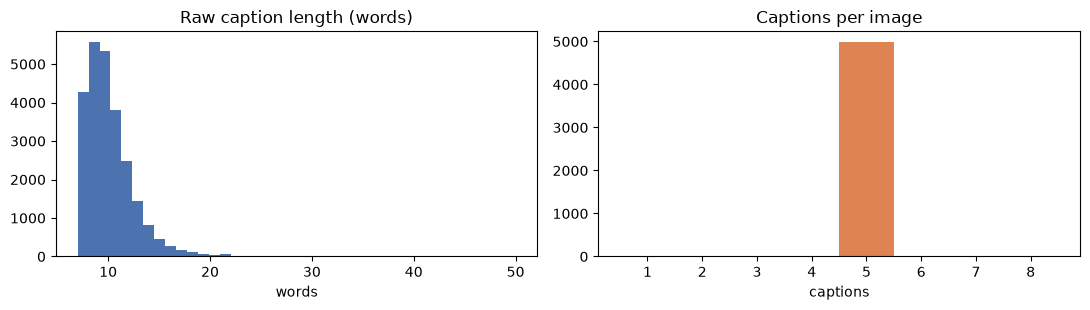

In [7]:
# Shape of the corpus before any cleaning -- the baseline the next section is measured against.
raw_words = pairs_all["caption_raw"].str.split().str.len()
raw_chars = pairs_all["caption_raw"].str.len()

raw_stats = {
    "n_candidate_pairs": int(len(pairs_all)),
    "n_distinct_images": int(pairs_all["image_id"].nunique()),
    "captions_per_image_mean": float(len(pairs_all) / pairs_all["image_id"].nunique()),
    "words": {"min": int(raw_words.min()), "median": float(raw_words.median()), "max": int(raw_words.max())},
    "chars": {"min": int(raw_chars.min()), "median": float(raw_chars.median()), "max": int(raw_chars.max())},
    "exact_duplicate_captions": int(pairs_all["caption_raw"].duplicated().sum()),
}

print("Raw caption statistics")
print(f"  words : min {raw_words.min():3d} | median {raw_words.median():5.1f} | max {raw_words.max():3d}")
print(f"  chars : min {raw_chars.min():3d} | median {raw_chars.median():5.1f} | max {raw_chars.max():3d}")
print(f"  exact duplicate captions : {pairs_all['caption_raw'].duplicated().sum():,}")
print(f"  saved -> {utils.save_table('raw_caption_stats', raw_stats)}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(raw_words, bins=40, color="#4C72B0")
axes[0].set_title("Raw caption length (words)")
axes[0].set_xlabel("words")
axes[1].hist(pairs_all.groupby("image_id").size(), bins=range(1, 10), color="#DD8452", align="left")
axes[1].set_title("Captions per image")
axes[1].set_xlabel("captions")
plt.tight_layout()
print(f"saved -> {utils.save_fig(fig, 'raw_caption_stats')}")
plt.show()


---
## 4. Caption Cleaning

→ `src/modules/data_preprocessing.py` — `clean_caption`, `clean_captions`, `filter_captions`

To get the captions ready for the text encoders we lowercase and strip them, remove special characters
and HTML artifacts, drop the ones that are empty, duplicated or too short or long, and normalise
whitespace and any character that would break tokenisation.

`clean_caption` does this with **regular expressions and libraries rather than hand-written character
lists**, which matters for coverage: a blacklist only removes the characters someone thought of, whereas
a **whitelist** regex (`[^a-z0-9\s'.,!?-]` → space) removes every character we did *not* think of,
including emoji, currency symbols and any stray Unicode in the corpus. Two libraries do the work that
would otherwise be hand-coded: **`ftfy`** repairs mojibake, and Python's **`html`** module unescapes
entities.

Order matters, because each step assumes the previous one has run:

| # | Step | Library / pattern | Example |
|---|------|-------------------|---------|
| 1 | mojibake repair | `ftfy.fix_text` | `cafÃ©` → `café` |
| 2 | HTML unescape + tag strip | `html.unescape`, regex | `&amp;` → `&`, `<br/>` → ` ` |
| 3 | URL removal | regex | `http://…` → ` ` |
| 4 | typographic folding | 3 regexes | `’ “ ” —` → `' " " -` |
| 5 | Unicode NFKD + ASCII fold | `unicodedata` | `café` → `cafe` |
| 6 | lowercase + strip | `str` | `A MAN ` → `a man` |
| 7 | **whitelist** regex | `[^a-z0-9\s'.,!?-]` | `sym©bols` → `symbols` |
| 8 | punctuation collapse | 2 regexes | `!!!` → `!`, `cat .` → `cat.` |
| 9 | whitespace normalisation | `\s+` → `" "` | `a\tb\nc\xa0d` → `a b c d` |

**We considered removing stop words with NLTK, and decided against it.** CLIP and BERT were both
pretrained on ordinary English containing words like "a", "on" and "with", so removing them would not
help the embeddings and would cost us meaning we need — *"a cat **on** a laptop"* and *"a cat **under** a
laptop"* are two different pictures.


In [8]:
# Every rule above, demonstrated on deliberately messy input.
demo = [
    "A  MAN   riding a HORSE on the beach.",
    "Two cats &amp; a dog <br/> sleeping.",
    "The caf\u00e9\u2019s sign reads \u201cOPEN\u201d \u2014 see http://example.com/menu",
    "What a view!!!   Really ???",
    "A\tplate\nof\xa0food   .",
    "Emoji \U0001F355 and sym\u00a9bols \u00bd removed",
    "   ",
]
print(f"{'RAW':<62} -> CLEANED")
print("-" * 104)
for s in demo:
    print(f"{s!r:<62} -> {prep.clean_caption(s)!r}")


RAW                                                            -> CLEANED
--------------------------------------------------------------------------------------------------------
'A  MAN   riding a HORSE on the beach.'                        -> 'a man riding a horse on the beach.'
'Two cats &amp; a dog <br/> sleeping.'                         -> 'two cats a dog sleeping.'
'The café’s sign reads “OPEN” — see http://example.com/menu'   -> "the cafe's sign reads open - see"
'What a view!!!   Really ???'                                  -> 'what a view! really?'
'A\tplate\nof\xa0food   .'                                     -> 'a plate of food.'
'Emoji 🍕 and sym©bols ½ removed'                               -> 'emoji and symbols 12 removed'
'   '                                                          -> ''


In [9]:
# Apply the cleaner to all ~25k candidate captions.
pairs_all = prep.clean_captions(pairs_all)

# How much of the cleaner is load-bearing on THIS corpus, as opposed to defensive?
rule_hits = prep.cleaning_rule_hits(pairs_all)

print()
print(f"Cleaned {rule_hits['n_captions']:,} captions")
print(f"  altered by cleaning       : {rule_hits['altered_by_cleaning']:,}")
print()
print("Which rules actually fire on this corpus")
print(f"  captions with non-ASCII characters : {rule_hits['with_non_ascii']:,}  (steps 1, 4, 5 are defensive)")
print(f"  captions with HTML entities/tags   : {rule_hits['with_html']:,}")
print(f"  captions with whitespace to fix    : {rule_hits['with_whitespace_to_fix']:,}")
print(f"  captions needing lowercasing       : {rule_hits['needing_lowercase']:,}")
print(f"  saved -> {utils.save_table('cleaning_rule_hits', rule_hits)}")


Cleaning captions:   0%|          | 0/25014 [00:00<?, ?it/s]


Cleaned 25,014 captions
  altered by cleaning       : 22,248

Which rules actually fire on this corpus
  captions with non-ASCII characters : 0  (steps 1, 4, 5 are defensive)
  captions with HTML entities/tags   : 0
  captions with whitespace to fix    : 3,802
  captions needing lowercasing       : 21,332
  saved -> outputs/tables/cleaning_rule_hits.json


In [10]:
# Filter, reporting how many rows each rule is responsible for removing. Doing this as a table rather
# than one chained expression makes it obvious if a single rule is dropping too much.
pairs_clean, stages = prep.filter_captions(pairs_all)

prev = None
print(f"{'STAGE':<36}{'REMAINING':>12}{'REMOVED':>10}")
print("-" * 58)
for name, n in stages:
    print(f"{name:<36}{n:>12,}{'' if prev is None else f'{prev - n:,}':>10}")
    prev = n

print()
print(f"Surviving captions : {len(pairs_clean):,} across {pairs_clean['image_id'].nunique():,} images")
filter_report = {
    "stages": [{"stage": name, "remaining": int(n)} for name, n in stages],
    "surviving_captions": int(len(pairs_clean)),
    "surviving_images": int(pairs_clean["image_id"].nunique()),
}
print(f"saved -> {utils.save_table('caption_filter_stages', filter_report)}")


STAGE                                  REMAINING   REMOVED
----------------------------------------------------------
start                                     25,014          
drop empty                                25,014         0
drop short (<3w / <10c)                   25,014         0
drop long (>60w / >250c)                  25,014         0
drop missing image file                   25,014         0
drop duplicate captions                   24,784       230

Surviving captions : 24,784 across 5,000 images
saved -> outputs/tables/caption_filter_stages.json


saved -> outputs/plots/caption_cleaning_examples.png


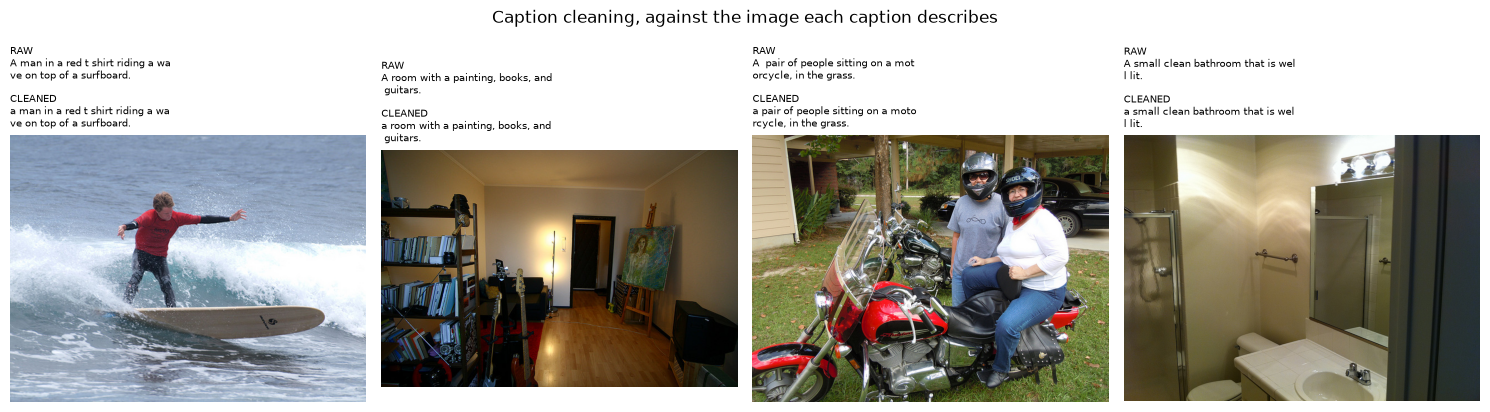

  000000121673.jpg
    raw     : 'A man in a red t shirt riding a wave on top of a surfboard.'
    cleaned : 'a man in a red t shirt riding a wave on top of a surfboard.'
  000000104666.jpg
    raw     : 'A room with a painting, books, and guitars. '
    cleaned : 'a room with a painting, books, and guitars.'
  000000068093.jpg
    raw     : 'A  pair of people sitting on a motorcycle, in the grass.'
    cleaned : 'a pair of people sitting on a motorcycle, in the grass.'
  000000058029.jpg
    raw     : 'A small clean bathroom that is well lit. '
    cleaned : 'a small clean bathroom that is well lit.'


In [11]:
# Cleaning shown against the image each caption describes, so the text can be checked for whether it
# still says what the picture shows.
changed = pairs_clean[pairs_clean["caption"] != pairs_clean["caption_raw"]]
examples = changed.sample(4, random_state=cfg.SEED).reset_index(drop=True)

fig, axes = plt.subplots(1, 4, figsize=(15, 4.6))
for ax, (_, row) in zip(axes, examples.iterrows()):
    ax.imshow(ImageOps.exif_transpose(Image.open(row["image_path"])).convert("RGB"))
    ax.axis("off")
    wrap = lambda s: "\n".join([s[i:i + 34] for i in range(0, min(len(s), 102), 34)])
    ax.set_title(f"RAW\n{wrap(row['caption_raw'])}\n\nCLEANED\n{wrap(row['caption'])}", fontsize=7, loc="left")

fig.suptitle("Caption cleaning, against the image each caption describes", y=1.02)
plt.tight_layout()
print(f"saved -> {utils.save_fig(fig, 'caption_cleaning_examples')}")
plt.show()

for _, row in examples.iterrows():
    print(f"  {row['file_name']}")
    print(f"    raw     : {row['caption_raw']!r}")
    print(f"    cleaned : {row['caption']!r}")


---
## 5. Subset Construction

→ `src/modules/data_preprocessing.py` — `build_subset`

From the cleaned pool we keep **3,000 distinct images with 2 captions each = 6,000 image–caption pairs**,
for the reasons set out in section 2.

Selection is deterministic: captions are ranked within each image by annotation id, images with at least
two surviving captions are eligible, and `N_IMAGES` of them are drawn with a seeded generator. Re-running
the notebook therefore produces exactly the same 6,000 rows.

Each row gets a `pair_idx` — `0 … 5,999` — which becomes the join key between the manifest and every
embedding array written in section 9. Row *i* of any `.npy` file is the caption on row *i* of the
manifest; nothing else needs to be tracked.


In [12]:
subset, subset_stats = prep.build_subset(pairs_clean)

if subset_stats["short_of_request"]:
    print(f"WARNING: only {subset_stats['n_distinct_images']:,} images are eligible, "
          f"fewer than the requested {cfg.N_IMAGES:,}")

print(f"Images with >= {cfg.CAPTIONS_PER_IMAGE} surviving captions : {subset_stats['eligible_images']:,}")
print(f"Curated subset : {subset_stats['n_pairs']:,} image-caption pairs")
print(f"  distinct images    : {subset_stats['n_distinct_images']:,}")
print(f"  captions per image : {subset_stats['captions_per_image']}")
print(f"  caption length     : mean {subset_stats['caption_words']['mean']:.1f} words | "
      f"min {subset_stats['caption_words']['min']} | max {subset_stats['caption_words']['max']}")
print(f"  saved -> {utils.save_table('subset_summary', subset_stats)}")
subset[["pair_idx", "image_id", "cap_rank", "file_name", "caption"]].head(6)


Images with >= 2 surviving captions : 5,000
Curated subset : 6,000 image-caption pairs
  distinct images    : 3,000
  captions per image : 2
  caption length     : mean 10.4 words | min 7 | max 29
  saved -> outputs/tables/subset_summary.json


,pair_idx,image_id,cap_rank,file_name,caption
0,0,632,0,000000000632.jpg,"bedroom scene with a bookcase, blue comforter ..."
1,1,632,1,000000000632.jpg,a bedroom with a bookshelf full of books.
2,2,776,0,000000000776.jpg,"three teddy bears, each a different color, snu..."
3,3,776,1,000000000776.jpg,three stuffed animals are sitting on a bed.
4,4,785,0,000000000785.jpg,a woman posing for the camera standing on skis.
5,5,785,1,000000000785.jpg,a woman standing on skiis while posing for the...


---
## 6. Image Preprocessing

→ `src/modules/data_preprocessing.py` — `preprocess_image`, with `resize_image` and `normalize_pixels`
underneath it, and `cache_resized_images` to run it over the subset

We resize every image to **512×512**, the resolution Stable Diffusion v1.x works at natively, normalise
the pixel values to the ranges the rest of the pipeline expects, and force a **consistent RGB 3-channel
format** so nothing downstream has to special-case a greyscale photo.

**Resize strategy.** A plain `resize((512, 512))` stretches non-square photos, and COCO images are mostly
640×480 — every one of them would come out horizontally squashed, distorting object geometry in a dataset
whose whole purpose is object-level semantics. Instead `resize_image` does an aspect-preserving resize of
the shorter side followed by a centre crop (`PIL.ImageOps.fit`), giving exactly 512×512 with no warping.
EXIF orientation is applied first, or a handful of photos arrive rotated 90°.

**Two normalisations**, because different consumers want different ranges:

| Range | `normalize_pixels(img, ...)` | Consumed by |
|-------|------------------------------|-------------|
| `[0, 1]` | `value_range="01"` | display, metrics, FID feature extractors |
| `[-1, 1]` | `value_range="pm1"` | the Stable Diffusion VAE encoder |

**What is cached, and why not tensors.** Only the **3,000 distinct images** are processed, not 6,000 — the
two captions of an image share one file. We cache them as JPEGs rather than as normalised tensors: 3,000
float32 tensors of shape `3×512×512` would be ~9.4 GB, while the JPEGs are a few hundred MB, and applying
the normalisation at load time is a cheap deterministic transform.


In [13]:
# Verify both transforms on a single image before processing 3,000 of them.
probe_path = subset.iloc[0]["image_path"]
probe_raw = Image.open(probe_path)
probe_512 = prep.preprocess_image(probe_path)
t01 = prep.normalize_pixels(probe_512, "01")
tpm = prep.normalize_pixels(probe_512, "pm1")

print(f"Original  : {probe_raw.size} px, mode={probe_raw.mode}")
print(f"Processed : {probe_512.size} px, mode={probe_512.mode}")
print()
print(f"[0,1] tensor  : shape {tuple(t01.shape)}, dtype {t01.dtype}, range [{t01.min():.3f}, {t01.max():.3f}]")
print(f"[-1,1] tensor : shape {tuple(tpm.shape)}, dtype {tpm.dtype}, range [{tpm.min():.3f}, {tpm.max():.3f}]")

assert t01.shape == (3, cfg.IMAGE_SIZE, cfg.IMAGE_SIZE)
assert 0.0 <= t01.min() and t01.max() <= 1.0
assert -1.0 <= tpm.min() and tpm.max() <= 1.0
print()
print("Both normalisations verified on a single image.")


Original  : (640, 483) px, mode=RGB
Processed : (512, 512) px, mode=RGB

[0,1] tensor  : shape (3, 512, 512), dtype torch.float32, range [0.000, 1.000]
[-1,1] tensor : shape (3, 512, 512), dtype torch.float32, range [-1.000, 1.000]

Both normalisations verified on a single image.


saved -> outputs/plots/image_preprocessing_examples.png


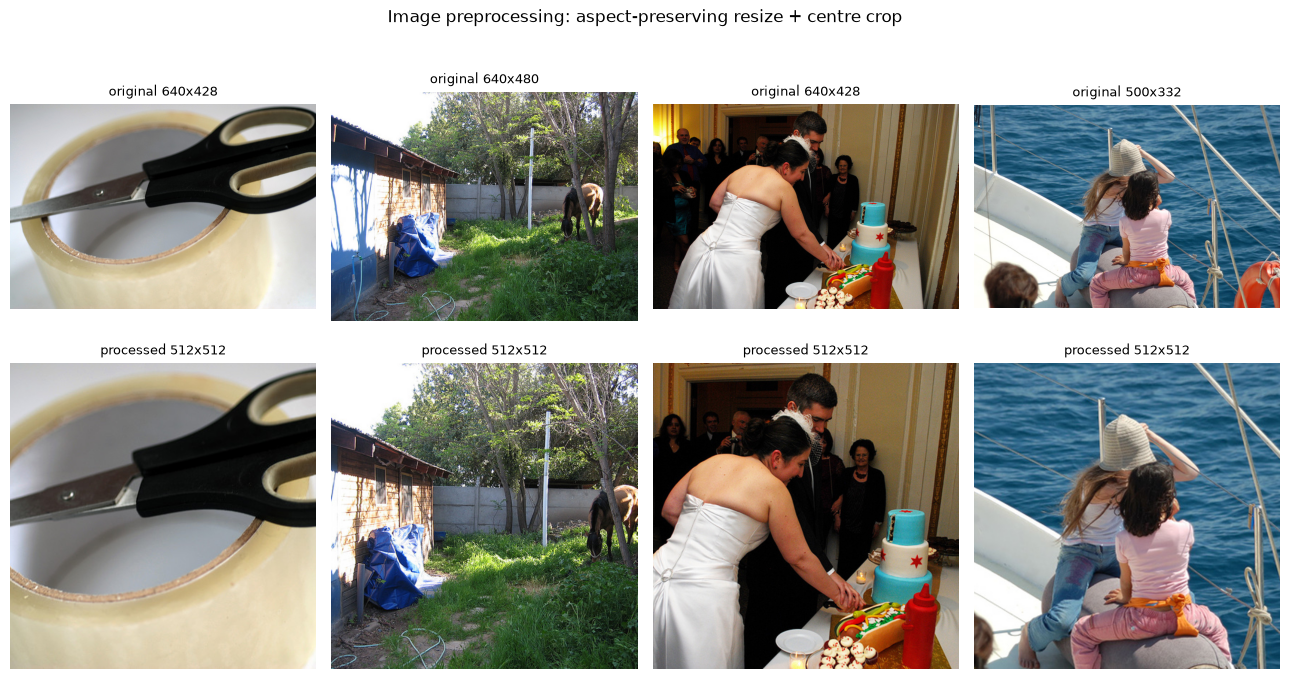

  000000348012.jpg : scissors are resting on a roll of clear tape.
  000000226883.jpg : an animal grazing on a lush field of green grass.
  000000350679.jpg : a newly married couple cutting up a giant hot dog cake.
  000000046497.jpg : two little girls sitting on the side of a white boat.


In [14]:
# Before / after, to confirm the centre crop is keeping the subject rather than cutting it off.
show = subset.drop_duplicates("image_id").sample(4, random_state=cfg.SEED)
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for col, (_, row) in enumerate(show.iterrows()):
    orig = ImageOps.exif_transpose(Image.open(row["image_path"])).convert("RGB")
    axes[0, col].imshow(orig)
    axes[0, col].set_title(f"original {orig.size[0]}x{orig.size[1]}", fontsize=9)
    axes[1, col].imshow(prep.preprocess_image(row["image_path"]))
    axes[1, col].set_title(f"processed {cfg.IMAGE_SIZE}x{cfg.IMAGE_SIZE}", fontsize=9)
    for r in (0, 1):
        axes[r, col].axis("off")

fig.suptitle("Image preprocessing: aspect-preserving resize + centre crop", y=0.98)
plt.tight_layout()
print(f"saved -> {utils.save_fig(fig, 'image_preprocessing_examples')}")
plt.show()

for _, row in show.iterrows():
    print(f"  {row['file_name']} : {row['caption']}")


In [15]:
# Process each distinct image once and cache the result. Files already present are skipped, so a
# re-run costs nothing.
subset, cache_info = prep.cache_resized_images(subset)

print()
print(f"Processed {cache_info['n_cached']:,}/{cache_info['n_distinct_images']:,} distinct images "
      f"in {cache_info['seconds']:.1f}s")
if cache_info["failures"]:
    print(f"Failures ({len(cache_info['failures'])}):")
    for name, err in cache_info["failures"][:10]:
        print(f"  {name}: {err}")

print(f"Cache size: {cache_info['cache_mb']:,.0f} MB in {utils.rel(cfg.IMAGES_512_DIR)}")
print(f"Pairs remaining: {cache_info['n_pairs_remaining']:,}")


Resizing to 512x512:   0%|          | 0/3000 [00:00<?, ?it/s]


Processed 3,000/3,000 distinct images in 0.3s
Cache size: 316 MB in data/processed/images_512
Pairs remaining: 6,000


In [16]:
# Validate the cache: every cached file must be exactly 512x512 RGB, with pixels in the stated ranges.
check = subset.drop_duplicates("image_id").sample(
    min(200, subset["image_id"].nunique()), random_state=cfg.SEED)
sizes, modes = prep.validate_cache(check["image_512_path"])

print(f"Validated {len(check)} cached images")
print(f"  distinct sizes : {sizes}")
print(f"  distinct modes : {modes}")
assert sizes == {(cfg.IMAGE_SIZE, cfg.IMAGE_SIZE)}, f"Unexpected sizes: {sizes}"
assert modes == {"RGB"}, f"Unexpected modes: {modes}"

batch01 = torch.stack([prep.normalize_pixels(Image.open(p), "01")
                       for p in check["image_512_path"][:64]])
batchpm = batch01 * 2.0 - 1.0
print()
print(f"Sample batch shape : {tuple(batch01.shape)}  (N, C, H, W)")
print(f"  [0,1]  range {batch01.min():.3f} .. {batch01.max():.3f} | mean {batch01.mean():.3f} | std {batch01.std():.3f}")
print(f"  [-1,1] range {batchpm.min():.3f} .. {batchpm.max():.3f} | mean {batchpm.mean():.3f} | std {batchpm.std():.3f}")
print()
print("All sampled images are 512x512 RGB with pixel values in the expected ranges.")


Validated 200 cached images
  distinct sizes : {(512, 512)}
  distinct modes : {'RGB'}



Sample batch shape : (64, 3, 512, 512)  (N, C, H, W)
  [0,1]  range 0.000 .. 1.000 | mean 0.446 | std 0.275
  [-1,1] range -1.000 .. 1.000 | mean -0.109 | std 0.550

All sampled images are 512x512 RGB with pixel values in the expected ranges.


---
## 7. Text Embeddings — CLIP

→ `src/modules/clip_embeddings.py`, with caching from `src/modules/storage.py`

CLIP was trained on hundreds of millions of image–caption pairs with a **contrastive** objective: pull a
matching image and caption together in a shared space, push mismatched ones apart. Its text vectors
therefore live in a space organised by *visual* meaning, which is precisely what conditions a
text-to-image model — and it is why Stable Diffusion v1.5 uses a CLIP text encoder rather than a
general-purpose language model.

**Why we load two CLIP checkpoints.** They do two different jobs.

The first is **conditioning**: SD v1.5 was built on top of one specific text encoder,
`clip-vit-large-patch14`, and only understands vectors from that encoder. No substitutes.

The second is **checking our own data**: confirming a caption really does match the image it is paired
with needs a model that turns *both* text and images into vectors in one shared space.
`clip-vit-base-patch32` carries both towers, so a caption can be compared against a photo directly. It is
also the cheaper model, which matters since section 10 puts 500 images through it.

| Checkpoint | Output | Why we need it |
|---|---|---|
| `clip-vit-base-patch32` | pooled **512-d** joint-space vector | has a **vision tower too**, which is what makes the text↔image retrieval check in section 10 possible |
| `clip-vit-large-patch14` | **77 × 768** per-token states | the exact encoder SD v1.5 is conditioned on; the tensors the UNet cross-attends to |

The conditioning tensor is **77 × 768** — one vector per token, not one for the whole sentence — because
the generator reads the prompt token by token. That is how "a **red** bus" colours the bus instead of
tinting the whole picture red.

**Caching.** `storage.subset_fingerprint` hashes the embeddings against the exact caption list that
produced them, so changing `N_IMAGES`, the cleaning rules or `SEED` throws the cache out automatically.
Without that, a re-run could quietly pair new captions with old vectors.


In [17]:
captions = subset["caption"].tolist()

FINGERPRINT = storage.subset_fingerprint(captions)
CACHE_USABLE = storage.cache_is_usable(FINGERPRINT, prev_meta)
reuse_log = {}

print(f"Captions to encode : {len(captions):,}")
print(f"Subset fingerprint : {FINGERPRINT}")
print(f"Previous run       : {(prev_meta or {}).get('subset_fingerprint') or '(none)'}")
print(f"Cached embeddings reusable : {CACHE_USABLE}")
if prev_meta and prev_meta.get("subset_fingerprint") not in (None, FINGERPRINT):
    print("  -> the subset changed since the last run, so embeddings will be recomputed")


Captions to encode : 6,000
Subset fingerprint : 22953c9c94547b7b
Previous run       : 22953c9c94547b7b
Cached embeddings reusable : True


In [18]:
# The joint-space model always loads: sections 10 and 11 need its vision tower regardless of caching.
utils.set_seed()
clip_tok, clip_model, clip_proc = clip_embeddings.load_joint()

print(f"Loaded {cfg.CLIP_JOINT_MODEL}")
for k, v in clip_embeddings.describe(clip_model).items():
    print(f"  {k:<22}{v:,.0f}" if isinstance(v, float) else f"  {k:<22}{v}")


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loaded openai/clip-vit-base-patch32
  parameters_millions   151
  text_hidden_size      512
  vision_hidden_size    768
  joint_projection_dim  512


CLIP token budget  : 77 tokens
Our captions       : min 9 | median 13 | p95 18 | p99 22 | max 34
Over the limit     : 0 captions (0.00%)
Headroom left      : 43 tokens below the ceiling

What this means for cleaning:
  No caption is truncated, so MAX_WORDS = 60 is already a safe proxy for the
  77-token limit -- the longest caption uses 34 tokens for 29 words.
  No token-based filter is needed on this corpus.
  saved -> outputs/tables/caption_token_stats.json
saved -> outputs/plots/caption_token_lengths.png


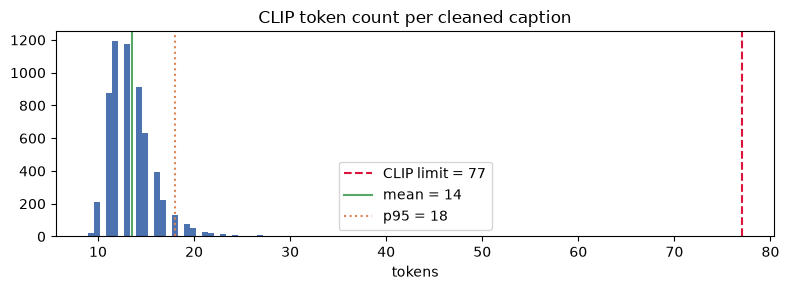

In [19]:
# CLIP's positional table stops at 77 tokens, so anything longer is silently truncated -- the model
# simply never sees the end of the caption. Measure where our captions sit against that ceiling, and
# check whether our word-count filter is already enough to keep us under it.
tok_len = clip_embeddings.token_lengths(captions, clip_tok)
n_truncated = int((tok_len > cfg.CLIP_MAX_TOKENS).sum())
p50, p95, p99 = (float(np.percentile(tok_len, q)) for q in (50, 95, 99))
headroom = cfg.CLIP_MAX_TOKENS - int(tok_len.max())

token_stats = {
    "clip_max_tokens": cfg.CLIP_MAX_TOKENS,
    "min": int(tok_len.min()), "mean": float(tok_len.mean()),
    "p50": p50, "p95": p95, "p99": p99, "max": int(tok_len.max()),
    "n_truncated": n_truncated,
    "pct_truncated": float(100 * n_truncated / len(tok_len)),
    "headroom_tokens": headroom,
    "max_words_filter": cfg.MAX_WORDS,
}

print(f"CLIP token budget  : {cfg.CLIP_MAX_TOKENS} tokens")
print(f"Our captions       : min {tok_len.min()} | median {p50:.0f} | p95 {p95:.0f} | "
      f"p99 {p99:.0f} | max {tok_len.max()}")
print(f"Over the limit     : {n_truncated} captions ({100 * n_truncated / len(tok_len):.2f}%)")
print(f"Headroom left      : {headroom} tokens below the ceiling")
print()
print("What this means for cleaning:")
if n_truncated == 0:
    print(f"  No caption is truncated, so MAX_WORDS = {cfg.MAX_WORDS} is already a safe proxy for the")
    print(f"  {cfg.CLIP_MAX_TOKENS}-token limit -- the longest caption uses "
          f"{tok_len.max()} tokens for {subset['n_words'].max()} words.")
    print("  No token-based filter is needed on this corpus.")
else:
    print(f"  {n_truncated} captions lose their tail. Lowering MAX_WORDS, or filtering on token count")
    print(f"  directly, would keep every caption inside the {cfg.CLIP_MAX_TOKENS}-token window.")
print(f"  saved -> {utils.save_table('caption_token_stats', token_stats)}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(tok_len, bins=40, color="#4C72B0")
ax.axvline(cfg.CLIP_MAX_TOKENS, color="crimson", ls="--", label=f"CLIP limit = {cfg.CLIP_MAX_TOKENS}")
ax.axvline(tok_len.mean(), color="#55A868", ls="-", label=f"mean = {tok_len.mean():.0f}")
ax.axvline(p95, color="#DD8452", ls=":", label=f"p95 = {p95:.0f}")
ax.set_title("CLIP token count per cleaned caption")
ax.set_xlabel("tokens")
ax.legend()
plt.tight_layout()
print(f"saved -> {utils.save_fig(fig, 'caption_token_lengths')}")
plt.show()


In [20]:
clip_text_emb, t_clip_joint = storage.load_or_encode(
    ["clip_text_joint"],
    lambda: clip_embeddings.encode_text(captions, clip_tok, clip_model),
    n_rows=len(captions), cache_usable=CACHE_USABLE, reuse_log=reuse_log,
)
print()
print(f"CLIP joint-space embeddings : {clip_text_emb.shape}  dtype={clip_text_emb.dtype}")
print(f"Time: {t_clip_joint:.1f}s" if t_clip_joint else "Loaded from cache")


Reusing cached: clip_text_joint.npy

CLIP joint-space embeddings : (6000, 512)  dtype=float32
Loaded from cache


In [21]:
# The Stable Diffusion v1.5 conditioning encoder.
sd_tok, sd_text = clip_embeddings.load_sd_text_encoder()
print(f"Loaded {cfg.CLIP_SD_MODEL}")
for k, v in clip_embeddings.describe(sd_text).items():
    print(f"  {k:<22}{v:,.0f}" if isinstance(v, float) else f"  {k:<22}{v}")

# The pooled vectors are small and always saved; the 77x768 sequence is saved only on request, because
# it is ~710 MB at this subset size and the encoder reproduces it deterministically in under a minute.
clip_seq_emb, clip_sd_pooled, t_clip_seq = storage.load_or_encode(
    ["clip_sd_sequence", "clip_sd_pooled"],
    lambda: clip_embeddings.encode_sequence(captions, sd_tok, sd_text),
    n_rows=len(captions), cache_usable=CACHE_USABLE,
    save=cfg.SAVE_SEQ_EMBEDDINGS, reuse_log=reuse_log,
)
if not cfg.SAVE_SEQ_EMBEDDINGS:
    storage.save_embedding("clip_sd_pooled", clip_sd_pooled)   # the small one is always persisted
    reuse_log["clip_sd_pooled"] = "computed"

print()
print(f"CLIP sequence embeddings : {clip_seq_emb.shape}  dtype={clip_seq_emb.dtype}  "
      f"({clip_seq_emb.nbytes / 1024**2:.0f} MB in memory)")
print(f"CLIP pooled embeddings   : {clip_sd_pooled.shape}  dtype={clip_sd_pooled.dtype}")
print(f"Sequence tensors written to disk: {cfg.SAVE_SEQ_EMBEDDINGS}")
print(f"Time: {t_clip_seq:.1f}s" if t_clip_seq else "Loaded from cache")


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loaded openai/clip-vit-large-patch14
  parameters_millions   123
  hidden_size           768
  layers                12


CLIP sequence:   0%|          | 0/94 [00:00<?, ?it/s]


CLIP sequence embeddings : (6000, 77, 768)  dtype=float16  (677 MB in memory)
CLIP pooled embeddings   : (6000, 768)  dtype=float32
Sequence tensors written to disk: False
Time: 13.6s


In [22]:
# Because the 77x768 tensors are recomputed rather than stored, confirm the recomputation is in fact
# reproducible: encode the first batch again, with the same seed and the same batch size, and compare.
utils.set_seed()
recomputed, _ = clip_embeddings.encode_sequence(captions[:cfg.BATCH_SIZE], sd_tok, sd_text)

head = clip_seq_emb[:cfg.BATCH_SIZE]
max_delta = float(np.abs(recomputed.astype(np.float32) - head.astype(np.float32)).max())
identical = bool(np.array_equal(recomputed, head))

print(f"Re-encoded the first {cfg.BATCH_SIZE} captions with the same seed and batch size")
print(f"  bit-identical to the first pass : {identical}")
print(f"  max absolute difference         : {max_delta:.2e}")
assert max_delta < 1e-3, "Re-encoding did not reproduce the original tensors"
print()
print("Reproducible: the conditioning tensors can be regenerated on demand instead of stored.")


CLIP sequence:   0%|          | 0/1 [00:00<?, ?it/s]

Re-encoded the first 64 captions with the same seed and batch size


  bit-identical to the first pass : True
  max absolute difference         : 0.00e+00

Reproducible: the conditioning tensors can be regenerated on demand instead of stored.


---
## 8. Text Embeddings — BERT

→ `src/modules/bert_embeddings.py`

**BERT** (`bert-base-uncased`) is our comparison encoder: the same Transformer architecture class and
roughly the same size as CLIP's text tower, but trained with **masked language modelling on text alone**.
It has never seen an image.

That difference is the point. Both encoders produce 768-d sentence vectors that look equally reasonable
on paper, so the only way to tell them apart is to measure them — which is what section 10 does. The
expectation to test: CLIP should separate captions by *visual* content, BERT by *linguistic* similarity,
and only CLIP's space should line up with images at all.

**Why encode it now, in the same pass as CLIP.** The captions are already loaded, cleaned and curated at
this point, so running BERT over them here costs one extra pass over 6,000 short sentences. Leaving it
for later would mean rebuilding the whole subset just to feed a second encoder.

**Pooling.** BERT ships a `pooler_output`, but it is the tanh-projected `[CLS]` state trained for
next-sentence prediction, not for sentence similarity — using it as a sentence embedding is a
well-documented trap. `bert_embeddings.encode_text` computes two honest alternatives instead: the raw
`[CLS]` state, and the attention-mask-weighted **mean** over all real tokens, which is the one to prefer
when the two disagree.

This file is the template for adding another encoder: write one like it, add a call here, and nothing
else in the pipeline changes.


In [23]:
bert_tok, bert_model = bert_embeddings.load()
print(f"Loaded {cfg.BERT_MODEL}")
for k, v in bert_embeddings.describe(bert_model).items():
    print(f"  {k:<22}{v:,.0f}" if isinstance(v, float) else f"  {k:<22}{v:,}")

bert_cls_emb, bert_mean_emb, t_bert = storage.load_or_encode(
    ["bert_cls", "bert_mean"],
    lambda: bert_embeddings.encode_text(captions, bert_tok, bert_model),
    n_rows=len(captions), cache_usable=CACHE_USABLE, reuse_log=reuse_log,
)
print()
print(f"BERT [CLS] embeddings : {bert_cls_emb.shape}  dtype={bert_cls_emb.dtype}")
print(f"BERT mean embeddings  : {bert_mean_emb.shape}  dtype={bert_mean_emb.dtype}")
print(f"Time: {t_bert:.1f}s" if t_bert else "Loaded from cache")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loaded google-bert/bert-base-uncased
  hidden_size           768
  layers                12
  vocab_size            30,522
  parameters_millions   109
Reusing cached: bert_cls.npy, bert_mean.npy

BERT [CLS] embeddings : (6000, 768)  dtype=float32
BERT mean embeddings  : (6000, 768)  dtype=float32
Loaded from cache


---
## 9. Storage

→ `src/modules/storage.py`

Embeddings are persisted **alongside the image–caption pairs they came from**, so no later stage ever has
to re-run an encoder or re-derive which caption produced which vector.

```
data/processed/
├── pairs.parquet            # the curated manifest (pair_idx, image_id, caption, paths, ...)
├── pairs.csv                # the same, human-readable
├── metadata.json            # provenance: models, config, shapes, versions, timings
├── images_512/              # 512x512 RGB JPEG cache (one file per distinct image)
└── embeddings/
    ├── clip_text_joint.npy  # (N, 512)  float32   shared text/image space
    ├── clip_sd_pooled.npy   # (N, 768)  float32   SD v1.5 text encoder, pooled
    ├── bert_cls.npy         # (N, 768)  float32   [CLS] token
    └── bert_mean.npy        # (N, 768)  float32   mean-pooled
```

**The contract**: row *i* of every `.npy` is the caption at `pair_idx == i` in `pairs.parquet`. One join
key, enforced by an assertion before anything is written and verified by a round-trip read afterwards.

Figures and summary tables go somewhere separate, under `outputs/`, because they describe a *run* rather
than the dataset itself. Every path comes from `config.py`, so moving the artefacts is a one-line change.

`clip_sd_sequence.npy` — the `(N, 77, 768)` UNet conditioning tensors — is **deliberately not written**:
~710 MB for something the encoder reproduces deterministically in under a minute (verified in section 7).
Flip `SAVE_SEQ_EMBEDDINGS` in `config.py` to trade the disk for the time.


In [24]:
manifest = storage.write_manifest(subset)

print(f"Wrote the manifest: {len(manifest):,} rows")
print(f"  {utils.rel(cfg.MANIFEST_PARQUET)}")
print(f"  {utils.rel(cfg.MANIFEST_CSV)}")
manifest.head(4)


Wrote the manifest: 6,000 rows
  data/processed/pairs.parquet
  data/processed/pairs.csv


,pair_idx,image_id,ann_id,cap_rank,file_name,caption_raw,caption,n_words,n_chars,height,width,image_path,image_512_path
0,0,632,301804,0,000000000632.jpg,"Bedroom scene with a bookcase, blue comforter ...","bedroom scene with a bookcase, blue comforter ...",9,57,483,640,data/val2017/000000000632.jpg,data/processed/images_512/000000000632.jpg
1,1,632,302791,1,000000000632.jpg,A bedroom with a bookshelf full of books.,a bedroom with a bookshelf full of books.,8,41,483,640,data/val2017/000000000632.jpg,data/processed/images_512/000000000632.jpg
2,2,776,637709,0,000000000776.jpg,"Three teddy bears, each a different color, snu...","three teddy bears, each a different color, snu...",9,62,640,428,data/val2017/000000000776.jpg,data/processed/images_512/000000000776.jpg
3,3,776,639641,1,000000000776.jpg,Three stuffed animals are sitting on a bed.,three stuffed animals are sitting on a bed.,8,43,640,428,data/val2017/000000000776.jpg,data/processed/images_512/000000000776.jpg


In [25]:
# Embedding arrays. Every array is row-checked against the manifest before it is written.
arrays = {
    "clip_text_joint": clip_text_emb,
    "clip_sd_pooled": clip_sd_pooled,
    "bert_cls": bert_cls_emb,
    "bert_mean": bert_mean_emb,
}
if cfg.SAVE_SEQ_EMBEDDINGS:
    arrays["clip_sd_sequence"] = clip_seq_emb

print(f"{'ARRAY':<22}{'SHAPE':<22}{'DTYPE':<10}{'SIZE':>10}")
print("-" * 64)
for name, shape, dtype, mb in storage.save_arrays(arrays, manifest):
    print(f"{name:<22}{str(shape):<22}{dtype:<10}{mb:>8.1f} MB")
print("-" * 64)
print(f"{'total':<54}{sum(a.nbytes for a in arrays.values()) / 1024**2:>8.1f} MB")

# Report -- but never delete -- arrays left over from an earlier run with a different subset size.
stale = storage.find_stale(arrays, len(manifest))
if stale:
    print()
    print("STALE FILES from an earlier run with a different subset (left in place, safe to delete):")
    for path, shape, mb in stale:
        print(f"  {path}  {shape}  {mb:,.0f} MB")


ARRAY                 SHAPE                 DTYPE           SIZE
----------------------------------------------------------------
clip_text_joint       (6000, 512)           float32       11.7 MB
clip_sd_pooled        (6000, 768)           float32       17.6 MB
bert_cls              (6000, 768)           float32       17.6 MB
bert_mean             (6000, 768)           float32       17.6 MB
----------------------------------------------------------------
total                                                     64.5 MB


In [26]:
# Provenance, so a later run -- or a reader of the report -- knows exactly what produced these files.
metadata = storage.build_metadata(
    manifest=manifest,
    arrays=arrays,
    dataset_counts={
        "n_candidate_pairs": int(len(pairs_all)),
        "n_after_cleaning": int(len(pairs_clean)),
    },
    cleaning_steps=prep.CLEANING_STEPS,
    timings={"clip_joint": t_clip_joint, "clip_sequence": t_clip_seq, "bert": t_bert},
    fingerprint=FINGERPRINT,
    reuse_log=reuse_log,
    not_persisted=({} if cfg.SAVE_SEQ_EMBEDDINGS else {
        "clip_sd_sequence": {
            "shape": list(clip_seq_emb.shape), "dtype": str(clip_seq_emb.dtype),
            "reason": "~710 MB; deterministically regenerated by section 7 in under a minute",
        }
    }),
)
storage.save_metadata(metadata)

print(json.dumps(metadata, indent=2)[:1400])
print("...")


{
  "dataset": {
    "name": "COCO 2017 Captions",
    "split": "val2017",
    "annotations_file": "data/annotations/captions_val2017.json",
    "n_candidate_pairs": 25014,
    "n_after_cleaning": 24784,
    "n_curated_pairs": 6000,
    "n_distinct_images": 3000,
    "captions_per_image": 2
  },
  "image_preprocessing": {
    "size": [
      512,
      512
    ],
    "mode": "RGB",
    "resize": "aspect-preserving shorter-side resize + centre crop (PIL ImageOps.fit, bicubic)",
    "exif_transpose": true,
    "normalisations": {
      "display_and_metrics": "[0, 1]",
      "sd_vae": "[-1, 1] via Normalize(0.5, 0.5)"
    },
    "cache_dir": "data/processed/images_512"
  },
  "caption_cleaning": {
    "steps": [
      "ftfy mojibake repair",
      "html unescape + tag strip",
      "url removal",
      "typographic folding (regex)",
      "unicode NFKD + ascii fold",
      "lowercase + strip",
      "whitelist regex",
      "punctuation collapse",
      "whitespace -> single space"
    ],

In [27]:
# Round-trip: reload everything from disk and confirm it matches what is in memory. Without this, a
# silent write failure would only surface in a later notebook.
rt = storage.verify_round_trip(manifest, arrays)
probe_img = Image.open(cfg.PROJECT_ROOT / rt["probe_image"])

print("Round-trip verified.")
print(f"  manifest rows : {rt['manifest_rows']:,}")
print(f"  arrays checked: {', '.join(rt['arrays_checked'])}")
print(f"  row 7 caption : {rt['probe_caption']!r}")
print(f"  row 7 image   : {rt['probe_image']} -> {probe_img.size} {probe_img.mode}")


Round-trip verified.

  manifest rows : 6,000
  arrays checked: clip_text_joint, bert_mean
  row 7 caption : 'a white oven and a white refrigerator are in the kitchen.'
  row 7 image   : data/processed/images_512/000000000802.jpg -> (512, 512) RGB


---
## 10. Sanity Checks

→ `src/modules/sanity_checks.py`

Matching shapes only prove the arrays are **well-formed**, not that they are **meaningful** — a bug that
encoded the same caption 6,000 times would pass a shape check. Four checks, cheapest first:

1. **Shape and numerical health** — expected dimensions, no `NaN`/`Inf`, sane vector norms.
2. **Text → image retrieval** — the real test. Encode images with CLIP's vision tower and check that each
   caption retrieves *its own* image out of 500. Chance is 1/500 = 0.2%.
3. **Sibling-caption agreement** — the two captions of one image describe the same scene, so they should
   land closer together than two random captions. Measurable for **every** encoder, BERT included, which
   is what makes the CLIP-vs-BERT comparison possible without an image tower.
4. **Nearest-neighbour inspection** — the qualitative read: what does each encoder *think* is similar?

**A note on retrieval with two captions per image.** Retrieval needs exactly one correct answer per
query, and our subset has two captions pointing at each image. Check 2 therefore runs over the **first
caption of each image only** (`cap_rank == 0`), so no two queries compete for the same target.

The module returns numbers; the plotting stays here, where the figures appear.


In [28]:
# --- Check 1: shapes and numerical health -------------------------------
expected = sanity_checks.expected_shapes(len(manifest))
health, all_ok = sanity_checks.embedding_health(arrays, expected)

print(f"{'ARRAY':<22}{'SHAPE':<22}{'EXPECTED':<22}{'NaN/Inf':<10}{'MEAN NORM':>10}")
print("-" * 86)
for name, h in health.items():
    ok = h["shape_ok"] and h["all_finite"]
    print(f"{name:<22}{str(tuple(h['shape'])):<22}{str(tuple(h['expected'])):<22}"
          f"{'none' if h['all_finite'] else 'FOUND':<10}{h['norm_mean']:>10.2f}"
          f"{'' if ok else '  <-- FAIL'}")

print("-" * 86)
print("All shapes match the manifest and all values are finite." if all_ok else "CHECK FAILED")
print(f"saved -> {utils.save_table('embedding_health', health)}")
assert all_ok


ARRAY                 SHAPE                 EXPECTED              NaN/Inf    MEAN NORM


--------------------------------------------------------------------------------------
clip_text_joint       (6000, 512)           (6000, 512)           none            8.02
clip_sd_pooled        (6000, 768)           (6000, 768)           none           27.75
bert_cls              (6000, 768)           (6000, 768)           none           15.28
bert_mean             (6000, 768)           (6000, 768)           none            9.98
--------------------------------------------------------------------------------------
All shapes match the manifest and all values are finite.
saved -> outputs/tables/embedding_health.json


In [29]:
# --- Check 2a: encode the retrieval image set with CLIP's vision tower ---
first_caps = manifest[manifest["cap_rank"] == 0].reset_index(drop=True)
align_rows = first_caps.head(min(cfg.N_ALIGN_IMAGES, len(first_caps)))
align_idx = align_rows["pair_idx"].to_numpy()
align_paths = [str(cfg.PROJECT_ROOT / p) for p in align_rows["image_512_path"]]
print(f"Retrieval set: {len(align_idx)} captions over {len(set(align_paths))} distinct images")

# Cached too -- encoding 500 images is the slowest check here.
clip_image_emb, t_align = storage.load_or_encode(
    ["clip_image_align"],
    lambda: clip_embeddings.encode_images(align_paths, clip_proc, clip_model),
    n_rows=len(align_paths), cache_usable=CACHE_USABLE, reuse_log=reuse_log,
)
print()
print(f"CLIP image embeddings: {clip_image_emb.shape}")


Retrieval set: 500 captions over 500 distinct images
Reusing cached: clip_image_align.npy

CLIP image embeddings: (500, 512)


In [30]:
# --- Check 2b: does each caption retrieve its own image? ----------------
ret = sanity_checks.retrieval(clip_text_emb[align_idx], clip_image_emb)

print(f"Text -> image retrieval over {ret['n_queries']} pairs")
print(f"  Recall@1  : {ret['recall_at_1']:6.1%}   (chance {ret['chance']:.2%}  ->  "
      f"{ret['times_better_than_chance']:,.0f}x better)")
print(f"  Recall@5  : {ret['recall_at_5']:6.1%}")
print(f"  Recall@10 : {ret['recall_at_10']:6.1%}")
print(f"  median rank of the correct image : {ret['median_rank_of_correct_image']} of {ret['n_queries']}")
print()
print(f"  cosine, matched pairs    : {ret['cosine_matched_mean']:.4f} +/- {ret['cosine_matched_std']:.4f}")
print(f"  cosine, mismatched pairs : {ret['cosine_mismatched_mean']:.4f} +/- {ret['cosine_mismatched_std']:.4f}")
print(f"  separation               : {ret['separation']:+.4f}")

retrieval_table = {k: v for k, v in ret.items()
                   if k not in ("sim", "ranks", "matched", "mismatched")}
print(f"  saved -> {utils.save_table('clip_retrieval_metrics', retrieval_table)}")

assert ret["recall_at_1"] > 10 * ret["chance"], "Retrieval is near chance -- the embeddings are not aligned"
assert ret["separation"] > 0, "Matched pairs should be more similar than mismatched pairs"
print()
print("PASS -- captions retrieve their own images far above chance.")


Text -> image retrieval over 500 pairs
  Recall@1  :  56.4%   (chance 0.20%  ->  282x better)
  Recall@5  :  87.6%
  Recall@10 :  94.6%
  median rank of the correct image : 1 of 500

  cosine, matched pairs    : 0.3080 +/- 0.0346
  cosine, mismatched pairs : 0.1539 +/- 0.0414
  separation               : +0.1541
  saved -> outputs/tables/clip_retrieval_metrics.json

PASS -- captions retrieve their own images far above chance.


saved -> outputs/plots/clip_matched_vs_mismatched.png


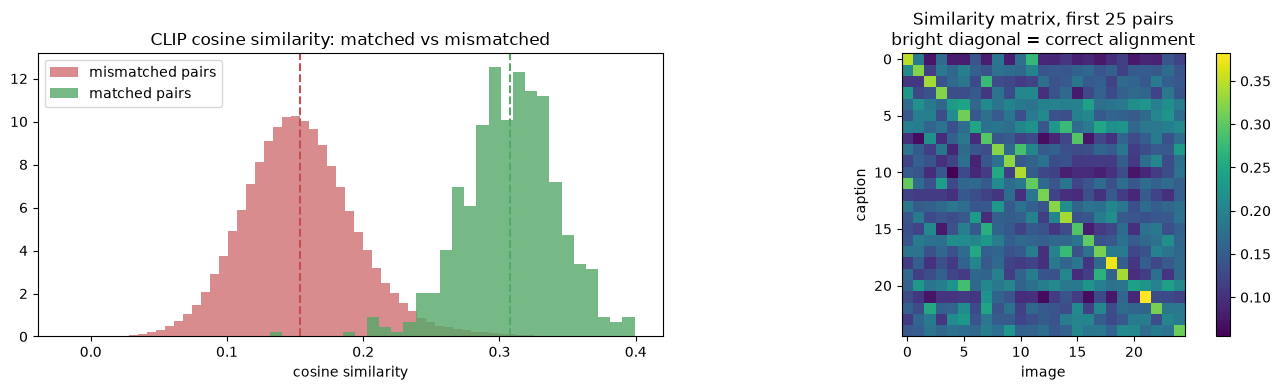

In [31]:
sim, matched, mismatched = ret["sim"], ret["matched"], ret["mismatched"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(mismatched, bins=60, alpha=0.65, label="mismatched pairs", color="#C44E52", density=True)
axes[0].hist(matched, bins=30, alpha=0.80, label="matched pairs", color="#55A868", density=True)
axes[0].axvline(mismatched.mean(), color="#C44E52", ls="--")
axes[0].axvline(matched.mean(), color="#55A868", ls="--")
axes[0].set_title("CLIP cosine similarity: matched vs mismatched")
axes[0].set_xlabel("cosine similarity")
axes[0].legend()

k = 25
im = axes[1].imshow(sim[:k, :k], cmap="viridis")
axes[1].set_title(f"Similarity matrix, first {k} pairs\nbright diagonal = correct alignment")
axes[1].set_xlabel("image")
axes[1].set_ylabel("caption")
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
print(f"saved -> {utils.save_fig(fig, 'clip_matched_vs_mismatched')}")
plt.show()


saved -> outputs/plots/clip_retrieval_top3.png


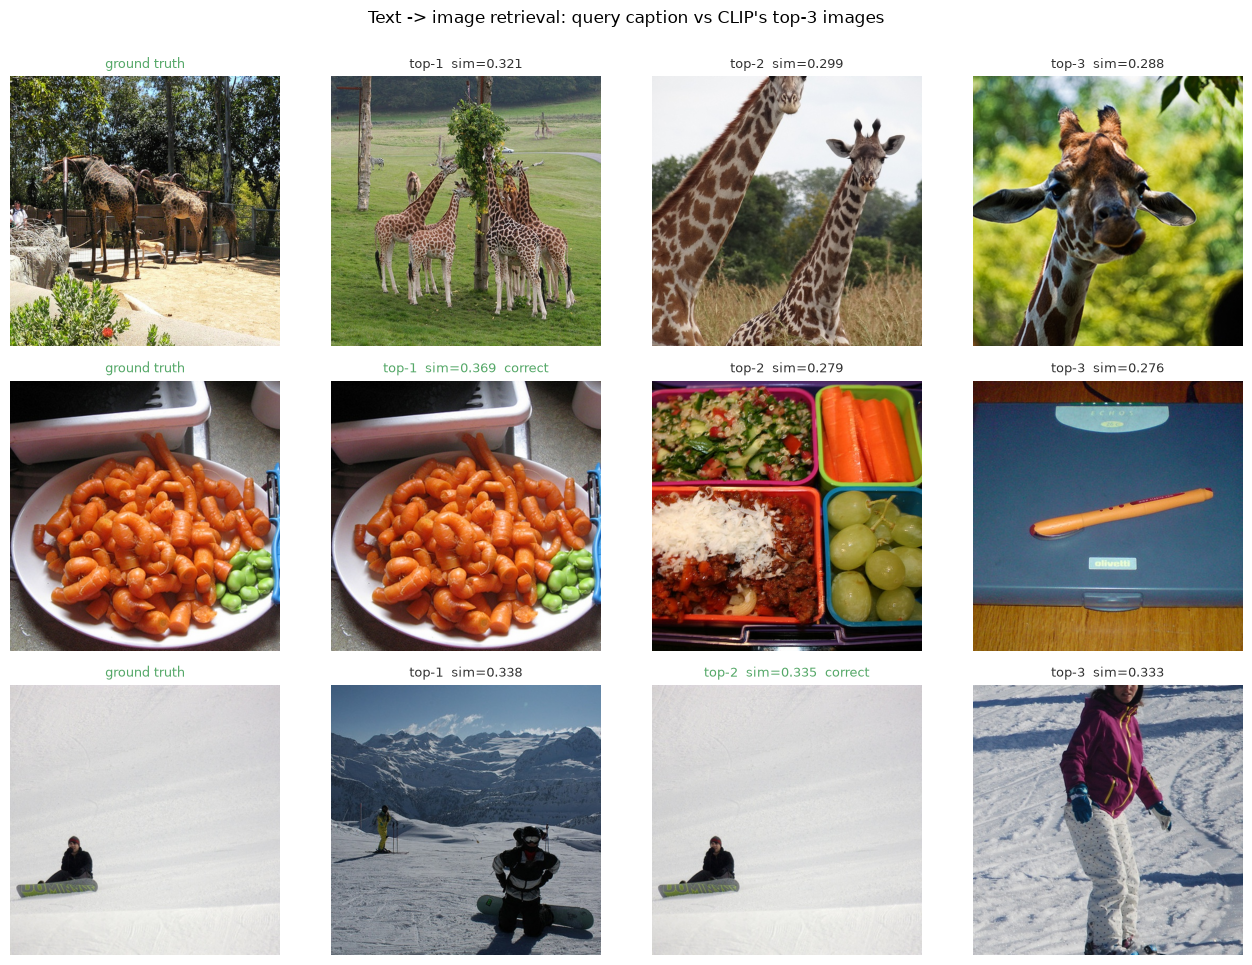

query 1: 'two giraffe walking next to each other in a forest.'
query 2: 'a plate topped with baby carrots and beans next to a peeler.'
query 3: 'a person sitting on the side of a mountain with a snow board.'


In [32]:
# The qualitative view of the same check: a caption and the three images CLIP ranks highest for it.
rng = np.random.default_rng(cfg.SEED)
n_show = 3
picks = rng.choice(ret["n_queries"], n_show, replace=False)
ranks = ret["ranks"]

fig, axes = plt.subplots(n_show, 4, figsize=(13, 3.2 * n_show))
for r, qi in enumerate(picks):
    axes[r, 0].imshow(Image.open(align_paths[qi]))
    axes[r, 0].set_title("ground truth", fontsize=9, color="#55A868")
    axes[r, 0].axis("off")
    for c, ci in enumerate(ranks[qi][:3]):
        axes[r, c + 1].imshow(Image.open(align_paths[ci]))
        axes[r, c + 1].set_title(f"top-{c + 1}  sim={sim[qi, ci]:.3f}{'  correct' if ci == qi else ''}",
                                 fontsize=9, color="#55A868" if ci == qi else "#333333")
        axes[r, c + 1].axis("off")

fig.suptitle("Text -> image retrieval: query caption vs CLIP's top-3 images", y=1.0)
plt.tight_layout()
print(f"saved -> {utils.save_fig(fig, 'clip_retrieval_top3')}")
plt.show()

for r, qi in enumerate(picks):
    print(f"query {r + 1}: {manifest.iloc[align_idx[qi]]['caption']!r}")


In [33]:
# --- Check 3: do the two captions of one image land near each other? ----
# This is the check BERT can take part in: no image tower required, only the knowledge that two rows
# describe the same scene.
pair_a = manifest[manifest["cap_rank"] == 0].sort_values("image_id")["pair_idx"].to_numpy()
pair_b = manifest[manifest["cap_rank"] == 1].sort_values("image_id")["pair_idx"].to_numpy()
assert len(pair_a) == len(pair_b)

encoders = {
    "CLIP joint": clip_text_emb,
    "CLIP SD pooled": clip_sd_pooled,
    "BERT [CLS]": bert_cls_emb,
    "BERT mean": bert_mean_emb,
}
sibling = sanity_checks.sibling_gap(encoders, pair_a, pair_b, rng)

print(f"Sibling captions (same image) vs random caption pairs, over {len(pair_a):,} images")
print()
print(f"{'ENCODER':<20}{'SIBLING COS':>13}{'RANDOM COS':>13}{'GAP':>9}")
print("-" * 55)
for label, s in sibling.items():
    print(f"{label:<20}{s['sibling_cos']:>13.4f}{s['random_cos']:>13.4f}{s['gap']:>+9.4f}")

best = max(sibling.items(), key=lambda kv: kv[1]["gap"])
print()
print(f"Largest gap: {best[0]} ({best[1]['gap']:+.4f})")
print(f"saved -> {utils.save_table('encoder_sibling_scores', sibling)}")
print("A larger gap means the encoder places two descriptions of one scene closer together than two")
print("unrelated captions -- it is encoding meaning rather than surface word overlap. A high sibling")
print("cosine with an equally high random cosine means the opposite: everything is mapped into a")
print("narrow cone, so the rankings carry little information. Watch for that on the [CLS] row.")


Sibling captions (same image) vs random caption pairs, over 3,000 images

ENCODER               SIBLING COS   RANDOM COS      GAP
-------------------------------------------------------
CLIP joint                 0.7884       0.5104  +0.2780
CLIP SD pooled             0.6478       0.2324  +0.4154
BERT [CLS]                 0.8420       0.7919  +0.0501
BERT mean                  0.8097       0.6867  +0.1231

Largest gap: CLIP SD pooled (+0.4154)
saved -> outputs/tables/encoder_sibling_scores.json
A larger gap means the encoder places two descriptions of one scene closer together than two
unrelated captions -- it is encoding meaning rather than surface word overlap. A high sibling
cosine with an equally high random cosine means the opposite: everything is mapped into a
narrow cone, so the rankings carry little information. Watch for that on the [CLS] row.


saved -> outputs/plots/encoder_sibling_gap.png


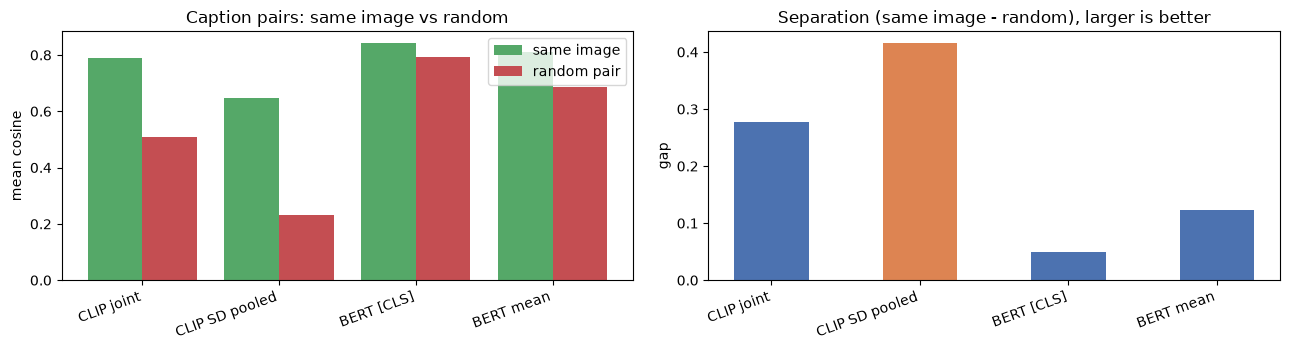

In [34]:
# The same comparison as a chart. The bar pair matters more than either bar alone -- it is the gap
# that says whether the encoder separates meaning.
labels = list(sibling)
sib_means = [sibling[k]["sibling_cos"] for k in labels]
rnd_means = [sibling[k]["random_cos"] for k in labels]
gaps = [sibling[k]["gap"] for k in labels]
x = np.arange(len(labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].bar(x - 0.2, sib_means, 0.4, label="same image", color="#55A868")
axes[0].bar(x + 0.2, rnd_means, 0.4, label="random pair", color="#C44E52")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=20, ha="right")
axes[0].set_ylabel("mean cosine")
axes[0].set_title("Caption pairs: same image vs random")
axes[0].legend()

axes[1].bar(x, gaps, 0.5, color=["#4C72B0" if g < max(gaps) else "#DD8452" for g in gaps])
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=20, ha="right")
axes[1].set_ylabel("gap")
axes[1].set_title("Separation (same image - random), larger is better")

plt.tight_layout()
print(f"saved -> {utils.save_fig(fig, 'encoder_sibling_gap')}")
plt.show()


In [35]:
# --- Check 4: nearest-neighbour captions, per encoder -------------------
query_idx = int(align_idx[picks[0]])
print(f"QUERY: {manifest.iloc[query_idx]['caption']!r}")
print()
for label, emb in encoders.items():
    idx, sims = sanity_checks.top_neighbours(emb, query_idx, k=5)
    print(label)
    for j, s in zip(idx, sims):
        print(f"   {s:.3f}  {manifest.iloc[int(j)]['caption']}")
    print()


QUERY: 'two giraffe walking next to each other in a forest.'

CLIP joint
   0.903  two giraffes walking next to each other in a field.
   0.879  two giraffe standing next to each other on a field.
   0.876  two giraffe moving very quickly in the woods.
   0.869  two giraffes walking in long grass near short trees.
   0.865  two giraffes standing around in the middle of a field.

CLIP SD pooled
   0.862  two giraffe moving very quickly in the woods.
   0.857  two giraffes walking next to each other in a field.
   0.823  two giraffe standing next to each other on a field.
   0.774  two giraffe are out in the wilderness looking at the camera.
   0.774  two giraffes walking in long grass near short trees.

BERT [CLS]
   0.986  two giraffes walking next to each other in a field.
   0.984  two giraffe standing next to each other on a field.
   0.975  three giraffes standing up in a field eating leaves off of trees.
   0.965  a herd of giraffe standing next to each other next to a pond.
   0.

---
## 11. Prompt → Image Test Runs

This is the end-to-end test of everything above, so it stays in the notebook rather than moving into a
module: five **cleaned captions from the curated subset** are fed to **Stable Diffusion v1.5** as prompts,
and each generated image is placed next to the real COCO photo that caption describes.

Using our own cleaned captions rather than invented prompts is deliberate — it tests the pipeline we
actually built, and it gives every generated image a **real photograph as a reference**, which is what
makes the CLIP-score comparison at the end meaningful.

The pipeline's text encoder is the same `clip-vit-large-patch14` whose embeddings we extracted in
section 7, so this run and those arrays are conditioned on the same vectors.

Generation settings come from `config.py` — `N_STEPS`, `GUIDANCE`, `IMAGE_SIZE`, one seeded generator per
prompt so the images are reproducible. Sweeping steps, guidance and schedulers is milestone 2, which is
exactly why those knobs now live in a config file instead of in a cell.

> First run downloads ~4 GB of weights. Set `RUN_SD_GENERATION = False` in `config.py` to skip.


In [36]:
sd_pipe, SD_REPO = None, None
if cfg.RUN_SD_GENERATION:
    from diffusers import StableDiffusionPipeline

    for repo in cfg.SD_REPO_CANDIDATES:
        try:
            print(f"Loading {repo} ...")
            try:
                sd_pipe = StableDiffusionPipeline.from_pretrained(
                    repo, dtype=cfg.SD_DTYPE, safety_checker=None, requires_safety_checker=False)
            except TypeError:                     # older diffusers spell it torch_dtype
                sd_pipe = StableDiffusionPipeline.from_pretrained(
                    repo, torch_dtype=cfg.SD_DTYPE, safety_checker=None, requires_safety_checker=False)
            SD_REPO = repo
            break
        except Exception as exc:                  # noqa: BLE001 - try the next mirror
            print(f"  unavailable ({type(exc).__name__}: {str(exc)[:120]})")

    if sd_pipe is not None:
        sd_pipe = sd_pipe.to(cfg.DEVICE)
        sd_pipe.set_progress_bar_config(disable=True)
        if cfg.DEVICE.type == "cuda":
            sd_pipe.enable_attention_slicing()    # keeps 512x512 comfortably inside a small VRAM budget
        print()
        print(f"Loaded {SD_REPO} on {cfg.DEVICE}")
        print(f"  text encoder : {type(sd_pipe.text_encoder).__name__} "
              f"(hidden {sd_pipe.text_encoder.config.hidden_size})")
        print(f"  scheduler    : {type(sd_pipe.scheduler).__name__}")
        print(f"  UNet params  : {sum(p.numel() for p in sd_pipe.unet.parameters()) / 1e6:.0f}M")
    else:
        print("\nNo Stable Diffusion checkpoint could be loaded -- skipping generation.")
else:
    print("RUN_SD_GENERATION is False -- skipping generation.")


Loading stable-diffusion-v1-5/stable-diffusion-v1-5 ...


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]


Loaded stable-diffusion-v1-5/stable-diffusion-v1-5 on cuda
  text encoder : CLIPTextModel (hidden 768)
  scheduler    : PNDMScheduler
  UNet params  : 860M


In [37]:
# Prompts from the curated subset, long enough to describe a scene rather than a single object.
prompt_rows = (
    manifest[(manifest["n_words"] >= cfg.PROMPT_MIN_WORDS) & (manifest["n_words"] <= cfg.PROMPT_MAX_WORDS)]
    .sample(cfg.N_PROMPTS, random_state=cfg.SEED)
    .reset_index(drop=True)
)

print(f"{cfg.N_PROMPTS} test prompts (cleaned COCO captions from the curated subset):")
print()
for i, row in prompt_rows.iterrows():
    print(f"  {i + 1}. {row['caption']}")
    print(f"     source image: {row['file_name']}")


5 test prompts (cleaned COCO captions from the curated subset):

  1. a biilboard with a railcar in front of it.
     source image: 000000148999.jpg
  2. there are two desktop computer and one laptop on the desk.
     source image: 000000547144.jpg
  3. a man sitting with headphones on near several birds.
     source image: 000000511076.jpg
  4. a group of people riding skis across a snow covered slope.
     source image: 000000341719.jpg
  5. a person standing snow wearing a snow suit and skis
     source image: 000000374369.jpg


In [38]:
results = []

if sd_pipe is not None:
    utils.set_seed()
    for i, row in prompt_rows.iterrows():
        # One generator seeded per prompt: re-running this cell reproduces these exact images.
        generator = torch.Generator(device=cfg.DEVICE).manual_seed(cfg.SEED + i)
        t0 = time.time()
        image = sd_pipe(
            row["caption"], num_inference_steps=cfg.N_STEPS, guidance_scale=cfg.GUIDANCE,
            height=cfg.IMAGE_SIZE, width=cfg.IMAGE_SIZE, generator=generator,
        ).images[0]
        dt = time.time() - t0

        out_path = cfg.GENERATIONS_DIR / f"run_{i + 1}_{row['image_id']}.png"
        image.save(out_path)
        results.append({"prompt": row["caption"], "image": image, "path": out_path,
                        "real": cfg.PROJECT_ROOT / row["image_512_path"], "seconds": dt,
                        "seed": cfg.SEED + i})
        print(f"[{i + 1}/{cfg.N_PROMPTS}] {dt:5.1f}s  seed={cfg.SEED + i}  {row['caption'][:60]}")

    print()
    print(f"Saved {len(results)} images to {utils.rel(cfg.GENERATIONS_DIR)}")
    print(f"Settings: {cfg.N_STEPS} steps, guidance {cfg.GUIDANCE}, {cfg.IMAGE_SIZE}x{cfg.IMAGE_SIZE}")
else:
    print("Generation skipped.")


[1/5]   5.1s  seed=42  a biilboard with a railcar in front of it.


[2/5]   4.1s  seed=43  there are two desktop computer and one laptop on the desk.


[3/5]   4.0s  seed=44  a man sitting with headphones on near several birds.


[4/5]   4.1s  seed=45  a group of people riding skis across a snow covered slope.


[5/5]   4.1s  seed=46  a person standing snow wearing a snow suit and skis

Saved 5 images to outputs/generations
Settings: 30 steps, guidance 7.5, 512x512


saved -> outputs/plots/prompt_to_image_runs.png


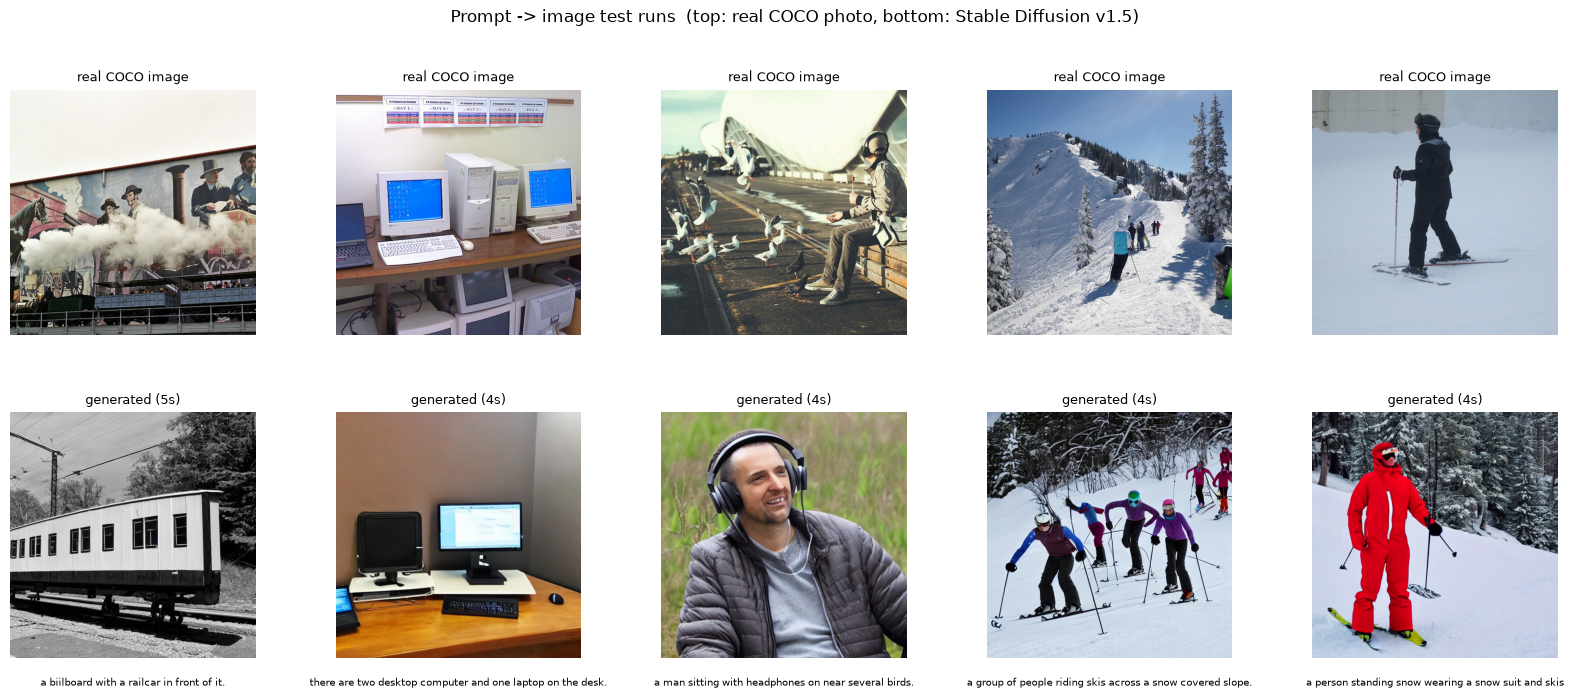

In [39]:
if results:
    fig, axes = plt.subplots(2, len(results), figsize=(3.2 * len(results), 7.2))
    for i, r in enumerate(results):
        axes[0, i].imshow(Image.open(r["real"]))
        axes[0, i].set_title("real COCO image", fontsize=9)
        axes[1, i].imshow(r["image"])
        axes[1, i].set_title(f"generated ({r['seconds']:.0f}s)", fontsize=9)
        for row_i in (0, 1):
            axes[row_i, i].axis("off")
        axes[1, i].text(0.5, -0.08, r["prompt"][:58], transform=axes[1, i].transAxes,
                        ha="center", va="top", fontsize=7, wrap=True)

    fig.suptitle("Prompt -> image test runs  (top: real COCO photo, bottom: Stable Diffusion v1.5)",
                 y=0.99)
    plt.tight_layout()
    print(f"saved -> {utils.save_fig(fig, 'prompt_to_image_runs')}")
    plt.show()
else:
    print("No generated images to display.")


#   CLIP(txt,gen)  CLIP(txt,real)  CLIP(gen,real)  PROMPT
----------------------------------------------------------------------------------------------------
1          0.3150          0.2391          0.5967  a biilboard with a railcar in front of it.
2          0.3022          0.2981          0.7769  there are two desktop computer and one lapto
3          0.3172          0.3838          0.5787  a man sitting with headphones on near severa
4          0.3349          0.3325          0.8493  a group of people riding skis across a snow 
5          0.3267          0.3384          0.8299  a person standing snow wearing a snow suit a
----------------------------------------------------------------------------------------------------
avg        0.3192          0.3184          0.7263
saved -> outputs/tables/generation_runs.json
saved -> outputs/plots/clip_scores_per_prompt.png


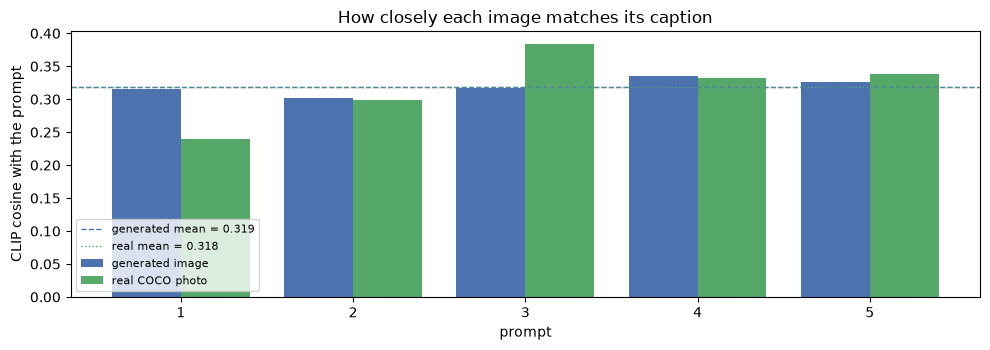

In [40]:
# CLIP cosine similarity for each run: prompt vs generated image, prompt vs real photo, and the two
# images against each other.
if results:
    gen_score, real_score, gen_vs_real = sanity_checks.clip_scores(
        prompts=[r["prompt"] for r in results],
        generated_images=[r["image"] for r in results],
        real_images=[r["real"] for r in results],
        tokenizer=clip_tok, model=clip_model, processor=clip_proc,
    )

    print(f"{'#':<3}{'CLIP(txt,gen)':>14}{'CLIP(txt,real)':>16}{'CLIP(gen,real)':>16}  PROMPT")
    print("-" * 100)
    for i, r in enumerate(results):
        print(f"{i + 1:<3}{gen_score[i]:>14.4f}{real_score[i]:>16.4f}{gen_vs_real[i]:>16.4f}  "
              f"{r['prompt'][:44]}")
    print("-" * 100)
    print(f"{'avg':<3}{gen_score.mean():>14.4f}{real_score.mean():>16.4f}{gen_vs_real.mean():>16.4f}")

    runs_table = {
        "settings": {"model": SD_REPO, "steps": cfg.N_STEPS, "guidance": cfg.GUIDANCE,
                     "size": [cfg.IMAGE_SIZE, cfg.IMAGE_SIZE], "seeds": [r["seed"] for r in results]},
        "runs": [
            {"prompt": r["prompt"], "image": utils.rel(r["path"]),
             "seconds": round(r["seconds"], 1), "seed": r["seed"],
             "clip_text_generated": float(gen_score[i]),
             "clip_text_real": float(real_score[i]),
             "clip_generated_real": float(gen_vs_real[i])}
            for i, r in enumerate(results)
        ],
        "means": {"clip_text_generated": float(gen_score.mean()),
                  "clip_text_real": float(real_score.mean()),
                  "clip_generated_real": float(gen_vs_real.mean())},
    }
    print(f"saved -> {utils.save_table('generation_runs', runs_table)}")

    x = np.arange(len(results))
    fig, ax = plt.subplots(figsize=(10, 3.6))
    ax.bar(x - 0.2, gen_score, 0.4, label="generated image", color="#4C72B0")
    ax.bar(x + 0.2, real_score, 0.4, label="real COCO photo", color="#55A868")
    ax.axhline(gen_score.mean(), color="#4C72B0", ls="--", lw=1,
               label=f"generated mean = {gen_score.mean():.3f}")
    ax.axhline(real_score.mean(), color="#55A868", ls=":", lw=1,
               label=f"real mean = {real_score.mean():.3f}")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{i + 1}" for i in x])
    ax.set_xlabel("prompt")
    ax.set_ylabel("CLIP cosine with the prompt")
    ax.set_title("How closely each image matches its caption")
    ax.legend(fontsize=8)
    plt.tight_layout()
    print(f"saved -> {utils.save_fig(fig, 'clip_scores_per_prompt')}")
    plt.show()


### Reading the table

Every number is a **cosine similarity in CLIP's joint space**, the shared space where a sentence vector
and an image vector can be compared directly. The scale runs from -1 to 1, but text-image scores sit in
a narrow band in practice: roughly **0.25–0.35** for a caption and an image that genuinely match, and
around 0.1 for an unrelated pair.

| Column | Compares | The question it answers |
|--------|----------|-------------------------|
| `CLIP(txt,gen)` | prompt vs generated image | did the model draw what the prompt asked for? |
| `CLIP(txt,real)` | prompt vs the real COCO photo | how well does that caption match its own photograph? |
| `CLIP(gen,real)` | generated image vs real photo | how close are the two pictures to each other? |

Three things to read off it:

- **`CLIP(txt,gen)` landing inside the 0.25–0.35 band** means the prompt survived the whole pipeline —
  cleaning, tokenising, encoding and conditioning — and reached the UNet intact. That is what this run
  is checking.
- **`CLIP(txt,real)` is the reference column.** It is the score a *real* photograph gets against the same
  caption, so it sets the scale for the first column rather than being a target to beat. Individual rows
  go either way: a generated image can score higher than the real photo, because it renders the
  caption's literal content without the incidental clutter a real scene contains.
- **`CLIP(gen,real)` is on a different scale entirely** and runs much higher, because two images share
  far more structure with each other than a sentence ever shares with an image. Compare it across rows,
  never against the first two columns.

What these numbers do **not** measure is whether the images look real. CLIP score captures agreement
with the prompt, not fidelity or diversity — that is what FID and Inception Score are for, in the
evaluation stage.


---
## 12. Artefacts

The inventory below is what this notebook leaves on disk. The written-up version — what each artefact is
for and which milestone consumes it — lives in **[`docs/milestone_1_artifacts.md`](../../docs/milestone_1_artifacts.md)**,
so the report can be assembled without re-running anything.


In [41]:
print("ARTEFACTS")
print("-" * 86)
print(f"  {'data/processed/pairs.parquet':<52}{len(manifest):,} rows")
print(f"  {'data/processed/pairs.csv':<52}same, human-readable")
print(f"  {'data/processed/metadata.json':<52}provenance")
print(f"  {'data/processed/images_512/':<52}{manifest['image_id'].nunique():,} x "
      f"{cfg.IMAGE_SIZE}x{cfg.IMAGE_SIZE} RGB ({cache_info['cache_mb']:,.0f} MB)")
for name, arr in arrays.items():
    print(f"  {'data/processed/embeddings/' + name + '.npy':<52}{str(arr.shape):<20}"
          f"{arr.nbytes / 1024**2:>7.1f} MB")
if results:
    print(f"  {'outputs/generations/':<52}{len(results)} PNG test runs")

plots = sorted(cfg.PLOTS_DIR.glob("*.png"))
tables = sorted(cfg.TABLES_DIR.glob("*.json"))
print(f"  {'outputs/plots/':<52}{len(plots)} figures")
for f in plots:
    print(f"      {f.name}")
print(f"  {'outputs/tables/':<52}{len(tables)} summary tables")
for f in tables:
    print(f"      {f.name}")

print()
print("ENCODE TIME  (cached = loaded from disk)")
print("-" * 86)
for label, secs in (("CLIP joint", t_clip_joint), ("CLIP sequence", t_clip_seq), ("BERT", t_bert)):
    print(f"  {label:<24}" + (f"{secs:>7.1f}s" if secs else "  cached"))
print()
print(f"  subset fingerprint : {FINGERPRINT}")
for name, state in reuse_log.items():
    print(f"  {name:<24}{state}")


ARTEFACTS
--------------------------------------------------------------------------------------
  data/processed/pairs.parquet                        6,000 rows
  data/processed/pairs.csv                            same, human-readable
  data/processed/metadata.json                        provenance
  data/processed/images_512/                          3,000 x 512x512 RGB (316 MB)
  data/processed/embeddings/clip_text_joint.npy       (6000, 512)            11.7 MB
  data/processed/embeddings/clip_sd_pooled.npy        (6000, 768)            17.6 MB
  data/processed/embeddings/bert_cls.npy              (6000, 768)            17.6 MB
  data/processed/embeddings/bert_mean.npy             (6000, 768)            17.6 MB
  outputs/generations/                                5 PNG test runs
  outputs/plots/                                      9 figures
      caption_cleaning_examples.png
      caption_token_lengths.png
      clip_matched_vs_mismatched.png
      clip_retrieval_top3.png
      

---
### Where this leads next

Everything above is deliberately **training-free**: pretrained encoders, a pretrained generator, and a
dataset prepared so that the next stages only have to read it.

**Immediately reusable from here**

- `pairs.parquet` — the join key tying every embedding row to its caption and its image.
- `images_512/` — the real-image reference set. Use `prep.normalize_pixels(img, "pm1")` before the SD VAE
  encoder, or `"01"` for FID feature extraction.
- `clip_text_joint.npy` plus `sanity_checks.retrieval` — already an automated CLIP-score evaluator for
  generated images.
- `clip_embeddings.encode_sequence` — regenerates the `77 × 768` UNet conditioning tensors on demand,
  deterministically.

**The open design question, stated now because it shapes the next stage.** A pretrained diffusion model
only understands the embedding space it was trained in: BERT vectors cannot be fed to Stable Diffusion's
UNet as-is, and with a few thousand pairs and a single Kaggle T4, unfreezing the UNet to teach it a new
space is not realistic. Section 10's comparison is what makes that concrete rather than assumed — it
shows *how* the two spaces differ, which is the evidence behind choosing one of:

1. **Compare pretrained models that already use different text encoders** (CLIP-conditioned vs
   T5-conditioned), which needs no training at all and fits the compute budget. Switching the encoder is
   now a new file in `src/modules/` plus one call here, not a rewrite.
2. **Freeze both models and train only a small projection layer** mapping BERT's space into SD's
   conditioning space — far cheaper than unfreezing, with weaker images expected. Explaining *why* they
   are weaker, with section 10's numbers as evidence, is itself a result.

**Then**: guidance-scale and inference-step sweeps, noise-schedule and scheduler comparisons, and FID and
Inception Score against the 3,000-image real set prepared here. Those knobs are already in `config.py`.
